In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
%pip install -q torch captum lifelines

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 455.2/455.2 kB 5.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 409.1/409.1 kB 22.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 118.9/118.9 kB 7.4 MB/s eta 0:00:00


In [3]:
import os
import json
import platform
import random
import warnings

import numpy as np
import pandas as pd

import torch
import torch.nn as nn

import matplotlib.pyplot as plt
import seaborn as sns

import captum
from captum.attr import DeepLiftShap, IntegratedGradients, GradientShap
from lifelines.utils import concordance_index
from scipy.stats import spearmanr

from IPython.display import display

sns.set_theme(style="whitegrid")
warnings.filterwarnings("ignore")

Reproducibility information

In [4]:
RANDOM_STATE = 42

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_seed(RANDOM_STATE)

print("Python:", platform.python_version())
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("PyTorch:", torch.__version__)
print("Captum:", captum.__version__)
print("Random state:", RANDOM_STATE)

Python: 3.12.13
NumPy: 2.0.2
Pandas: 2.2.2
PyTorch: 2.11.0+cpu
Captum: 0.9.0
Random state: 42


In [5]:
PROCESSED_DATA_DIR = "/content/drive/MyDrive/IEEE Project/Hepatocellular Carcinoma/Processed Data/"
UNICOX_OUTPUT_DIR = "/content/drive/MyDrive/IEEE Project/Hepatocellular Carcinoma/Processed Data/UnivariateCox/"
RESULTS_DIR = "/content/drive/MyDrive/IEEE Project/Hepatocellular Carcinoma/Results/"
XAI_RESULTS_DIR = RESULTS_DIR + "XAI/"
MODEL_DIR = "/content/drive/MyDrive/IEEE Project/Hepatocellular Carcinoma/Model/UnivariateCox/"

os.makedirs(XAI_RESULTS_DIR, exist_ok=True)

TRAIN_PATH = UNICOX_OUTPUT_DIR + "hcc_UniCox_train_selected.csv"
TEST_PATH = UNICOX_OUTPUT_DIR + "hcc_UniCox_test_selected.csv"
MODEL_PATH = MODEL_DIR + "hcc_UniCox_deepsurv_model.pth"

DURATION_COL = "OS_MONTHS"
EVENT_COL = "OS_EVENT"

BACKGROUND_SIZE = 100
TOP_N_FEATURES = 20
TOP_N_GENES = 30
TOP_N_WATERFALL = 12

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

Device: cpu


Load selected train and test data

In [6]:
train_data = pd.read_csv(TRAIN_PATH)
test_data = pd.read_csv(TEST_PATH)

print("Train data shape:", train_data.shape)
print("Test data shape:", test_data.shape)

test_data.head()

Train data shape: (1085, 52)
Test data shape: (272, 52)


,METASTASIS_Yes,CURATIVE_INTENT_SURGERY_Yes,CURATIVE_INTENT_SURGERY_No,METASTASIS_No,MAJOR_LIVER_RESECTION_,RESECTION_MARGIN_,RESECTION_MARGIN_R0,C_N_Yes,PNI_,LVI_,...,TUMOR_STAGE_Poorly differentiated,TUMOR_STAGE_Well differentiated,MUT_SHQ1,CNA_XPO1,CNA_REL,MUT_KRAS,NEOADJUVANT_SYSTEMIC_THERAPY_No,MUT_FGFR4,OS_MONTHS,OS_EVENT
0,0.0,0.0,1.0,1.0,1.0,1.0,0.0,1.0,1.0,1.0,...,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,28.980,1
1,0.0,0.0,1.0,1.0,1.0,1.0,0.0,1.0,1.0,1.0,...,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,5.952,1
2,1.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,1.0,...,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,9.984,0
3,1.0,0.0,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0,...,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,23.652,1
4,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,36.696,0


Basic checks

In [7]:
print("Train missing values:", int(train_data.isna().sum().sum()))
print("Test missing values:", int(test_data.isna().sum().sum()))

print("\nTrain OS_EVENT distribution:")
print(train_data[EVENT_COL].value_counts())

print("\nTest OS_EVENT distribution:")
print(test_data[EVENT_COL].value_counts())

Train missing values: 0
Test missing values: 0

Train OS_EVENT distribution:
OS_EVENT
1    641
0    444
Name: count, dtype: int64

Test OS_EVENT distribution:
OS_EVENT
1    161
0    111
Name: count, dtype: int64


ID leakage guard

In [8]:
for id_col in ["PATIENT_ID", "SAMPLE_ID"]:
    assert id_col not in train_data.columns, f"{id_col} found in train_data"
    assert id_col not in test_data.columns, f"{id_col} found in test_data"

print("ID leakage guard passed.")

ID leakage guard passed.


Define DeepSurv model class

In [9]:
class DeepSurv(nn.Module):
    def __init__(self, input_dim, hidden_layers, dropout_rate, activation_name):
        super(DeepSurv, self).__init__()

        activation_map = {
            "ReLU": nn.ReLU,
            "LeakyReLU": nn.LeakyReLU,
            "ELU": nn.ELU,
            "SELU": nn.SELU
        }

        layers = []
        current_dim = input_dim

        for hidden_dim in hidden_layers:
            layers.append(nn.Linear(current_dim, hidden_dim))
            layers.append(activation_map[activation_name]())
            if dropout_rate > 0:
                layers.append(nn.Dropout(dropout_rate))
            current_dim = hidden_dim

        self.feature_extractor = nn.Sequential(*layers)
        self.output_layer = nn.Linear(current_dim, 1)

    def forward(self, x):
        x = self.feature_extractor(x)
        return self.output_layer(x)

Load saved DeepSurv model

In [10]:
checkpoint = torch.load(MODEL_PATH, map_location=DEVICE)

INPUT_DIM = checkpoint["input_dim"]
HIDDEN_LAYERS = checkpoint["hidden_layers"]
DROPOUT_RATE = checkpoint["dropout_rate"]
ACTIVATION = checkpoint["activation"]
FEATURE_COLUMNS = checkpoint["feature_columns"]

print("Input dimension:", INPUT_DIM)
print("Hidden layers:", HIDDEN_LAYERS)
print("Dropout rate:", DROPOUT_RATE)
print("Activation:", ACTIVATION)
print("Feature count:", len(FEATURE_COLUMNS))

Input dimension: 50
Hidden layers: [128, 64]
Dropout rate: 0.2
Activation: ReLU
Feature count: 50


In [11]:
model = DeepSurv(
    input_dim=INPUT_DIM,
    hidden_layers=HIDDEN_LAYERS,
    dropout_rate=DROPOUT_RATE,
    activation_name=ACTIVATION
).to(DEVICE)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("Model loaded successfully")

Model loaded successfully


Create scalar risk-score wrapper for Captum
Captum attribution methods work most cleanly when the model returns one scalar output per patient. This wrapper exposes the DeepSurv risk score as a one-dimensional output while keeping the trained model unchanged.

In [12]:
class RiskScoreWrapper(nn.Module):
    def __init__(self, deepsurv_model):
        super(RiskScoreWrapper, self).__init__()
        self.deepsurv_model = deepsurv_model

    def forward(self, x):
        return self.deepsurv_model(x).squeeze(-1)


xai_model = RiskScoreWrapper(model).to(DEVICE)
xai_model.eval()

print("XAI wrapper ready")

XAI wrapper ready


Prepare feature matrices

In [13]:
X_train = train_data[FEATURE_COLUMNS].copy()
y_train = train_data[[DURATION_COL, EVENT_COL]].copy()

X_test = test_data[FEATURE_COLUMNS].copy()
y_test = test_data[[DURATION_COL, EVENT_COL]].copy()

assert X_train.shape[1] == INPUT_DIM
assert X_test.shape[1] == INPUT_DIM

print("Train feature shape:", X_train.shape)
print("Test feature shape:", X_test.shape)

Train feature shape: (1085, 50)
Test feature shape: (272, 50)


Confirm DeepSurv risk-score performance

In [14]:
X_test_tensor = torch.tensor(X_test.values, dtype=torch.float32).to(DEVICE)

with torch.no_grad():
    test_risk_scores = model(X_test_tensor).cpu().numpy().reshape(-1)

test_c_index = concordance_index(
    y_test[DURATION_COL].values,
    -test_risk_scores,
    y_test[EVENT_COL].values
)

print(f"Test Concordance Index: {test_c_index:.4f}")

Test Concordance Index: 0.7222


Build evaluation dataframe and representative patients

In [15]:
evaluation_df = y_test.copy()
evaluation_df["risk_score"] = test_risk_scores

high_risk_index = evaluation_df["risk_score"].idxmax()
low_risk_index = evaluation_df["risk_score"].idxmin()
median_risk_index = (
    evaluation_df["risk_score"]
    .sub(evaluation_df["risk_score"].median())
    .abs()
    .idxmin()
)

early_death_candidates = evaluation_df[
    (evaluation_df[EVENT_COL] == 1)
].sort_values(["risk_score", DURATION_COL], ascending=[False, True])

early_death_high_risk_index = early_death_candidates.index[0]

representative_patients = pd.DataFrame([
    {"patient_type": "Highest predicted risk", "test_index": high_risk_index},
    {"patient_type": "Lowest predicted risk", "test_index": low_risk_index},
    {"patient_type": "Median predicted risk", "test_index": median_risk_index},
    {"patient_type": "High-risk observed death", "test_index": early_death_high_risk_index},
])

representative_patients = representative_patients.merge(
    evaluation_df.reset_index().rename(columns={"index": "test_index"}),
    on="test_index",
    how="left"
).drop_duplicates("patient_type")

representative_patients

,patient_type,test_index,OS_MONTHS,OS_EVENT,risk_score
0,Highest predicted risk,68,2.232,1,2.797810
1,Lowest predicted risk,148,15.048,0,-2.425031
2,Median predicted risk,173,15.840,0,-0.058993
3,High-risk observed death,68,2.232,1,2.797810


Feature grouping and readable labels

In [16]:
def classify_feature(feature_name):
    if feature_name.startswith("MUT_"):
        return "Mutation"
    if feature_name.startswith("CNA_"):
        return "Copy number alteration"
    if any(key in feature_name for key in ["SURGERY", "THERAPY", "RESECTION_MARGIN"]):
        return "Treatment / surgery"
    if any(key in feature_name for key in ["METASTASIS", "TUMOR", "LVI", "PNI", "P_N", "C_N", "STAGE", "SITE", "MULTIFOCAL"]):
        return "Clinical / pathology"
    if any(key in feature_name for key in ["AGE", "BMI", "ETHNICITY"]):
        return "Demographic"
    if "GENE_PANEL" in feature_name or "SAMPLE" in feature_name:
        return "Sequencing / sample"
    return "Other"


def readable_label(feature_name):
    if feature_name.startswith("MUT_"):
        return feature_name.replace("MUT_", "") + " mutation"
    if feature_name.startswith("CNA_"):
        return feature_name.replace("CNA_", "") + " CNA"
    return feature_name.replace("_", " ")


def gene_symbol(feature_name):
    if feature_name.startswith("MUT_"):
        return feature_name.replace("MUT_", "")
    if feature_name.startswith("CNA_"):
        return feature_name.replace("CNA_", "")
    return np.nan


feature_metadata = pd.DataFrame({"feature": FEATURE_COLUMNS})
feature_metadata["readable_label"] = feature_metadata["feature"].apply(readable_label)
feature_metadata["feature_group"] = feature_metadata["feature"].apply(classify_feature)
feature_metadata["gene_symbol"] = feature_metadata["feature"].apply(gene_symbol)
feature_metadata["is_gene_feature"] = feature_metadata["feature"].str.startswith(("MUT_", "CNA_"))

print("Total features:", feature_metadata.shape[0])
print("Gene-derived features:", int(feature_metadata["is_gene_feature"].sum()))
print("Non-gene features:", int((~feature_metadata["is_gene_feature"]).sum()))

feature_metadata

Total features: 50
Gene-derived features: 17
Non-gene features: 33


,feature,readable_label,feature_group,gene_symbol,is_gene_feature
0,METASTASIS_Yes,METASTASIS Yes,Clinical / pathology,NaN,False
1,CURATIVE_INTENT_SURGERY_Yes,CURATIVE INTENT SURGERY Yes,Treatment / surgery,NaN,False
2,CURATIVE_INTENT_SURGERY_No,CURATIVE INTENT SURGERY No,Treatment / surgery,NaN,False
3,METASTASIS_No,METASTASIS No,Clinical / pathology,NaN,False
4,MAJOR_LIVER_RESECTION_,MAJOR LIVER RESECTION,Other,NaN,False
5,RESECTION_MARGIN_,RESECTION MARGIN,Treatment / surgery,NaN,False
6,RESECTION_MARGIN_R0,RESECTION MARGIN R0,Treatment / surgery,NaN,False
7,C_N_Yes,C N Yes,Clinical / pathology,NaN,False
8,PNI_,PNI,Clinical / pathology,NaN,False
9,LVI_,LVI,Clinical / pathology,NaN,False


Define attribution background samples
The background set represents reference training patients. It is used by DeepLiftShap and GradientSHAP, and the median training profile is used as the Integrated Gradients baseline.

In [17]:
background_size = min(BACKGROUND_SIZE, X_train.shape[0])

background_indices = (
    X_train
    .sample(n=background_size, random_state=RANDOM_STATE)
    .index
)

background_df = X_train.loc[background_indices].copy()
background_tensor = torch.tensor(background_df.values, dtype=torch.float32).to(DEVICE)

median_baseline = torch.tensor(
    X_train.median(axis=0).values.reshape(1, -1),
    dtype=torch.float32
).to(DEVICE)

X_test_tensor = torch.tensor(X_test.values, dtype=torch.float32).to(DEVICE)

print("Background tensor shape:", background_tensor.shape)
print("Median baseline shape:", median_baseline.shape)
print("Explanation tensor shape:", X_test_tensor.shape)

Background tensor shape: torch.Size([100, 50])
Median baseline shape: torch.Size([1, 50])
Explanation tensor shape: torch.Size([272, 50])


Attribution helper functions

In [18]:
def direction_from_signed_value(value):
    if value > 0:
        return "Risk-increasing"
    if value < 0:
        return "Protective"
    return "Neutral"


def build_importance_table(attributions, method_name):
    attr_df = pd.DataFrame(attributions, columns=FEATURE_COLUMNS)

    mean_abs = attr_df.abs().mean(axis=0)
    mean_signed = attr_df.mean(axis=0)
    positive_fraction = (attr_df > 0).mean(axis=0)

    importance_df = pd.DataFrame({
        "feature": FEATURE_COLUMNS,
        "mean_abs_attribution": mean_abs.values,
        "mean_signed_attribution": mean_signed.values,
        "positive_attribution_fraction": positive_fraction.values,
    })

    importance_df["method"] = method_name
    importance_df["readable_label"] = importance_df["feature"].apply(readable_label)
    importance_df["feature_group"] = importance_df["feature"].apply(classify_feature)
    importance_df["gene_symbol"] = importance_df["feature"].apply(gene_symbol)
    importance_df["is_gene_feature"] = importance_df["feature"].str.startswith(("MUT_", "CNA_"))
    importance_df["direction"] = importance_df["mean_signed_attribution"].apply(direction_from_signed_value)

    importance_df = importance_df.sort_values(
        "mean_abs_attribution",
        ascending=False
    ).reset_index(drop=True)
    importance_df["rank"] = np.arange(1, importance_df.shape[0] + 1)

    return importance_df, attr_df


def plot_importance_bar(importance_df, title, top_n=20, gene_only=False):
    plot_df = importance_df.copy()
    if gene_only:
        plot_df = plot_df[plot_df["is_gene_feature"]].copy()

    plot_df = plot_df.head(top_n).sort_values("mean_abs_attribution", ascending=True)

    plt.figure(figsize=(10, max(5, 0.35 * plot_df.shape[0])))
    sns.barplot(
        data=plot_df,
        x="mean_abs_attribution",
        y="readable_label",
        hue="direction",
        dodge=False,
        palette={"Risk-increasing": "#B22222", "Protective": "#1F77B4", "Neutral": "gray"}
    )
    plt.xlabel("Mean absolute attribution")
    plt.ylabel("Feature")
    plt.title(title)
    plt.legend(title="Mean signed direction", loc="lower right")
    plt.tight_layout()
    plt.show()


def plot_summary_beeswarm(attr_df, X_df, importance_df, title, top_n=20):
    top_features = importance_df.head(top_n)["feature"].tolist()
    plot_rows = []

    for feature in top_features:
        feature_values = X_df[feature].values
        feature_attributions = attr_df[feature].values

        min_value = np.nanmin(feature_values)
        max_value = np.nanmax(feature_values)
        if max_value > min_value:
            normalized_values = (feature_values - min_value) / (max_value - min_value)
        else:
            normalized_values = np.zeros_like(feature_values)

        for value, attribution, normalized_value in zip(feature_values, feature_attributions, normalized_values):
            plot_rows.append({
                "feature": readable_label(feature),
                "attribution": attribution,
                "feature_value_scaled": normalized_value
            })

    plot_df = pd.DataFrame(plot_rows)
    order = [readable_label(feature) for feature in top_features][::-1]

    plt.figure(figsize=(11, max(6, 0.38 * len(top_features))))
    sns.stripplot(
        data=plot_df,
        x="attribution",
        y="feature",
        order=order,
        hue="feature_value_scaled",
        palette="coolwarm",
        size=4,
        alpha=0.75,
        jitter=0.25
    )
    plt.axvline(0, color="black", linewidth=1)
    plt.xlabel("Attribution to DeepSurv risk score")
    plt.ylabel("Feature")
    plt.title(title)
    plt.legend(title="Scaled feature value", loc="lower right")
    plt.tight_layout()
    plt.show()


def plot_waterfall_for_patient(attr_df, patient_index, method_name, top_n=12):
    row = attr_df.loc[patient_index].copy()
    top_features = row.abs().sort_values(ascending=False).head(top_n).index.tolist()

    waterfall_df = pd.DataFrame({
        "feature": top_features,
        "attribution": row[top_features].values
    })
    waterfall_df["readable_label"] = waterfall_df["feature"].apply(readable_label)
    waterfall_df = waterfall_df.sort_values("attribution", ascending=True)
    waterfall_df["color"] = np.where(waterfall_df["attribution"] > 0, "#B22222", "#1F77B4")

    patient_row = evaluation_df.loc[patient_index]

    plt.figure(figsize=(10, max(5, 0.35 * waterfall_df.shape[0])))
    plt.barh(
        waterfall_df["readable_label"],
        waterfall_df["attribution"],
        color=waterfall_df["color"]
    )
    plt.axvline(0, color="black", linewidth=1)
    plt.xlabel("Attribution to DeepSurv risk score")
    plt.title(
        f"{method_name}: patient {patient_index} | "
        f"risk={patient_row['risk_score']:.3f} | "
        f"OS={patient_row[DURATION_COL]:.1f}m | "
        f"event={int(patient_row[EVENT_COL])}"
    )
    plt.tight_layout()
    plt.show()


def display_top_tables(importance_df, method_name):
    print(f"Top {TOP_N_FEATURES} full features by {method_name}")
    display(importance_df.head(TOP_N_FEATURES))

    print(f"Top {TOP_N_GENES} gene-derived features by {method_name}")
    gene_df = importance_df[importance_df["is_gene_feature"]].head(TOP_N_GENES)
    display(gene_df)
    return gene_df

DeepSHAP-style attribution using DeepLiftShap

In [19]:
set_seed(RANDOM_STATE)

deeplift_shap = DeepLiftShap(xai_model)

deepshap_attr = deeplift_shap.attribute(
    X_test_tensor,
    baselines=background_tensor
).detach().cpu().numpy()

deepshap_importance, deepshap_attr_df = build_importance_table(
    deepshap_attr,
    "DeepSHAP-style DeepLiftShap"
)

deepshap_gene_top = display_top_tables(
    deepshap_importance,
    "DeepSHAP-style DeepLiftShap"
)

Top 20 full features by DeepSHAP-style DeepLiftShap


,feature,mean_abs_attribution,mean_signed_attribution,positive_attribution_fraction,method,readable_label,feature_group,gene_symbol,is_gene_feature,direction,rank
0,CURATIVE_INTENT_SURGERY_Yes,0.198691,0.006661,0.591912,DeepSHAP-style DeepLiftShap,CURATIVE INTENT SURGERY Yes,Treatment / surgery,NaN,False,Risk-increasing,1
1,METASTASIS_Yes,0.180447,-0.049094,0.319853,DeepSHAP-style DeepLiftShap,METASTASIS Yes,Clinical / pathology,NaN,False,Protective,2
2,P_N_Negative,0.154629,0.018901,0.724265,DeepSHAP-style DeepLiftShap,P N Negative,Clinical / pathology,NaN,False,Risk-increasing,3
3,RESECTION_MARGIN_R0,0.148427,-0.039869,0.687500,DeepSHAP-style DeepLiftShap,RESECTION MARGIN R0,Treatment / surgery,NaN,False,Protective,4
4,TUMOR_STAGE_Poorly differentiated,0.102534,-0.013168,0.327206,DeepSHAP-style DeepLiftShap,TUMOR STAGE Poorly differentiated,Clinical / pathology,NaN,False,Protective,5
5,C_N_Yes,0.100240,-0.001958,0.363971,DeepSHAP-style DeepLiftShap,C N Yes,Clinical / pathology,NaN,False,Protective,6
6,METASTASIS_No,0.085523,-0.025392,0.330882,DeepSHAP-style DeepLiftShap,METASTASIS No,Clinical / pathology,NaN,False,Protective,7
7,PALLIATIVE_SYSTEMIC_THERPAY_No,0.080897,-0.022507,0.386029,DeepSHAP-style DeepLiftShap,PALLIATIVE SYSTEMIC THERPAY No,Other,NaN,False,Protective,8
8,LVI_,0.077319,-0.006706,0.386029,DeepSHAP-style DeepLiftShap,LVI,Clinical / pathology,NaN,False,Protective,9
9,DIAGNOSIS_AGE,0.075319,-0.023257,0.419118,DeepSHAP-style DeepLiftShap,DIAGNOSIS AGE,Demographic,NaN,False,Protective,10


Top 30 gene-derived features by DeepSHAP-style DeepLiftShap


,feature,mean_abs_attribution,mean_signed_attribution,positive_attribution_fraction,method,readable_label,feature_group,gene_symbol,is_gene_feature,direction,rank
15,MUT_KRAS,0.053392,0.007582,0.128676,DeepSHAP-style DeepLiftShap,KRAS mutation,Mutation,KRAS,True,Risk-increasing,16
17,CNA_CDKN2A,0.044873,0.013459,0.106618,DeepSHAP-style DeepLiftShap,CDKN2A CNA,Copy number alteration,CDKN2A,True,Risk-increasing,18
21,CNA_AXL,0.033654,-0.033654,0.000000,DeepSHAP-style DeepLiftShap,AXL CNA,Copy number alteration,AXL,True,Protective,22
23,CNA_CDKN2Ap14ARF,0.030566,0.008085,0.102941,DeepSHAP-style DeepLiftShap,CDKN2Ap14ARF CNA,Copy number alteration,CDKN2Ap14ARF,True,Risk-increasing,24
32,MUT_CD276,0.018830,-0.008259,0.003676,DeepSHAP-style DeepLiftShap,CD276 mutation,Mutation,CD276,True,Protective,33
33,CNA_PPP2R1A,0.016750,-0.016750,0.000000,DeepSHAP-style DeepLiftShap,PPP2R1A CNA,Copy number alteration,PPP2R1A,True,Protective,34
34,CNA_POLD1,0.016610,-0.016610,0.000000,DeepSHAP-style DeepLiftShap,POLD1 CNA,Copy number alteration,POLD1,True,Protective,35
37,MUT_ARID1A,0.015835,0.004669,0.386029,DeepSHAP-style DeepLiftShap,ARID1A mutation,Mutation,ARID1A,True,Risk-increasing,38
38,CNA_TP53,0.014232,0.014232,0.007353,DeepSHAP-style DeepLiftShap,TP53 CNA,Copy number alteration,TP53,True,Risk-increasing,39
41,CNA_CDKN2B,0.007930,0.000020,0.371324,DeepSHAP-style DeepLiftShap,CDKN2B CNA,Copy number alteration,CDKN2B,True,Risk-increasing,42


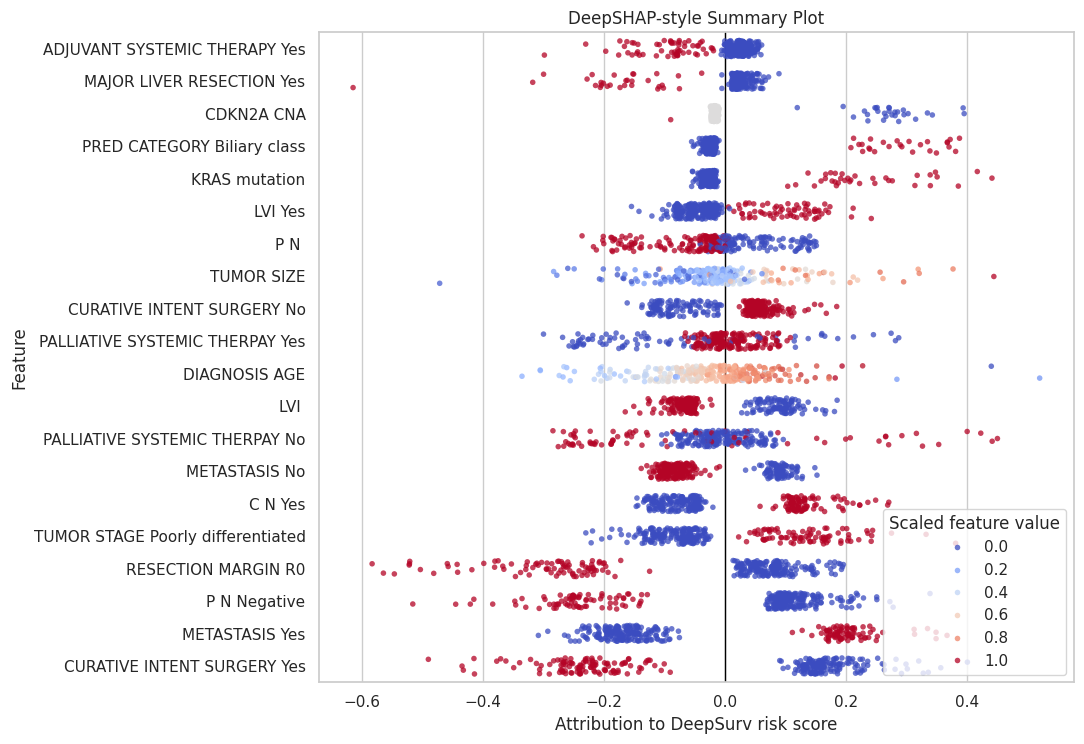

In [20]:
plot_summary_beeswarm(
    deepshap_attr_df,
    X_test,
    deepshap_importance,
    "DeepSHAP-style Summary Plot",
    top_n=TOP_N_FEATURES
)

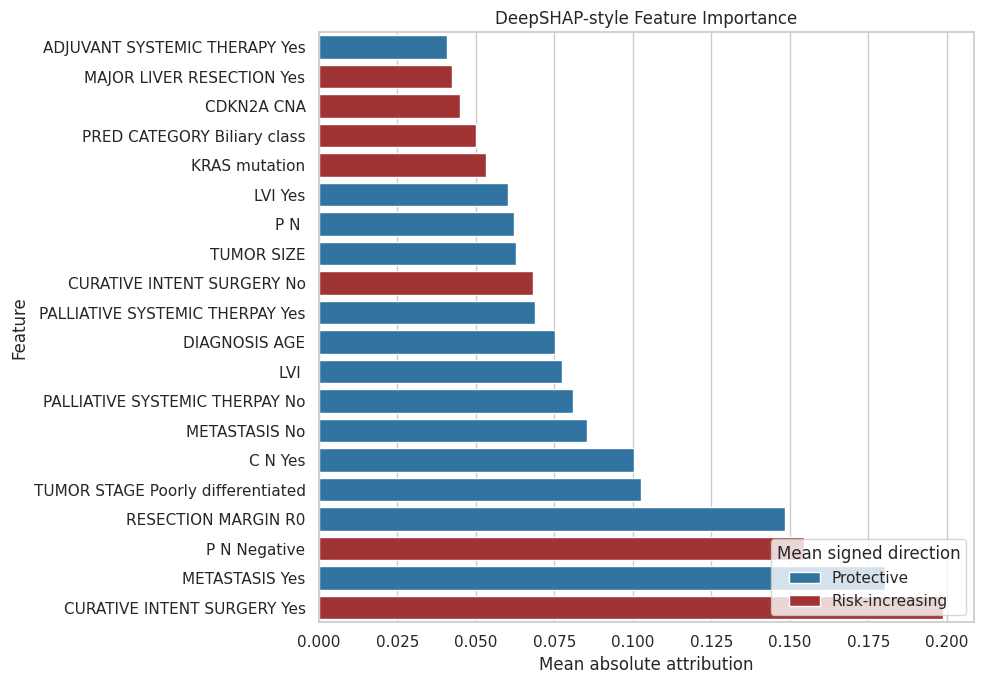

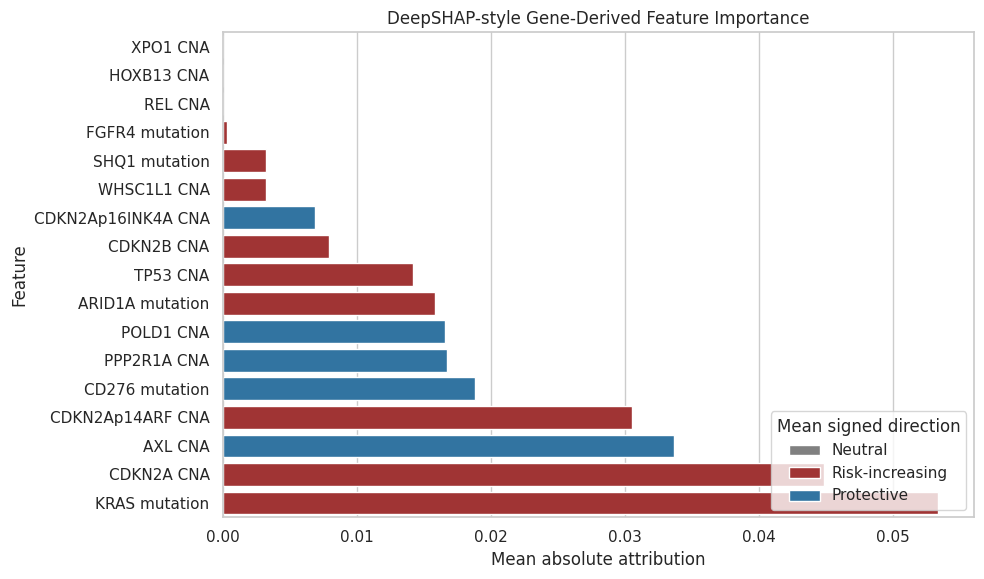

In [21]:
plot_importance_bar(
    deepshap_importance,
    "DeepSHAP-style Feature Importance",
    top_n=TOP_N_FEATURES,
    gene_only=False
)

plot_importance_bar(
    deepshap_importance,
    "DeepSHAP-style Gene-Derived Feature Importance",
    top_n=min(TOP_N_GENES, int(feature_metadata["is_gene_feature"].sum())),
    gene_only=True
)

DeepSHAP-style waterfall plots for representative patients

Highest predicted risk


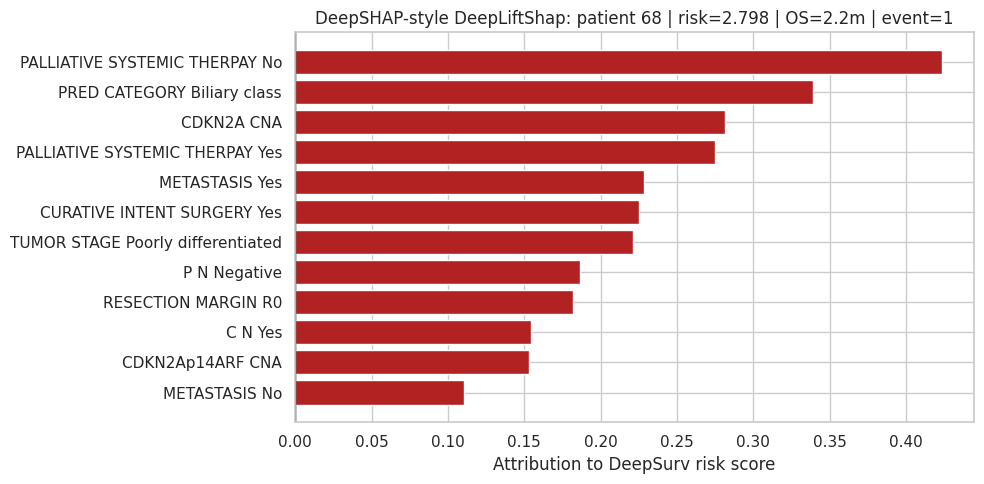

Lowest predicted risk


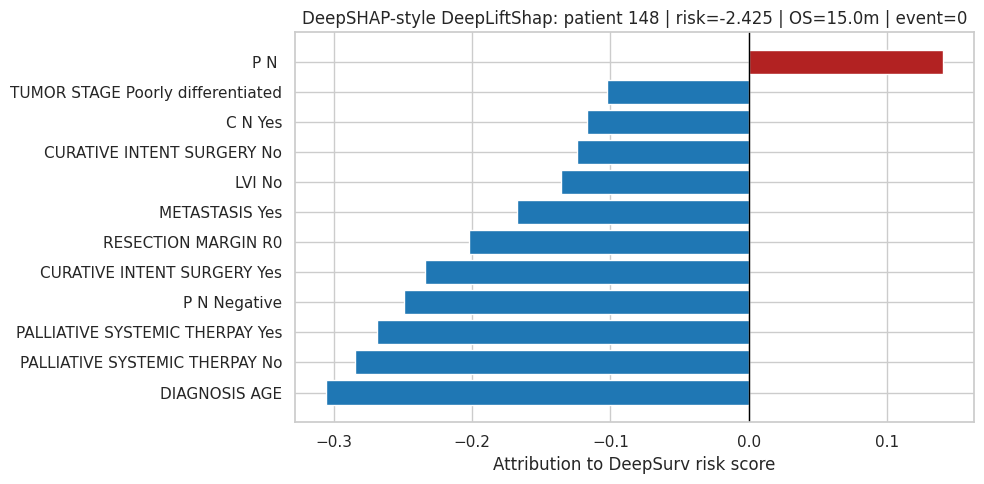

Median predicted risk


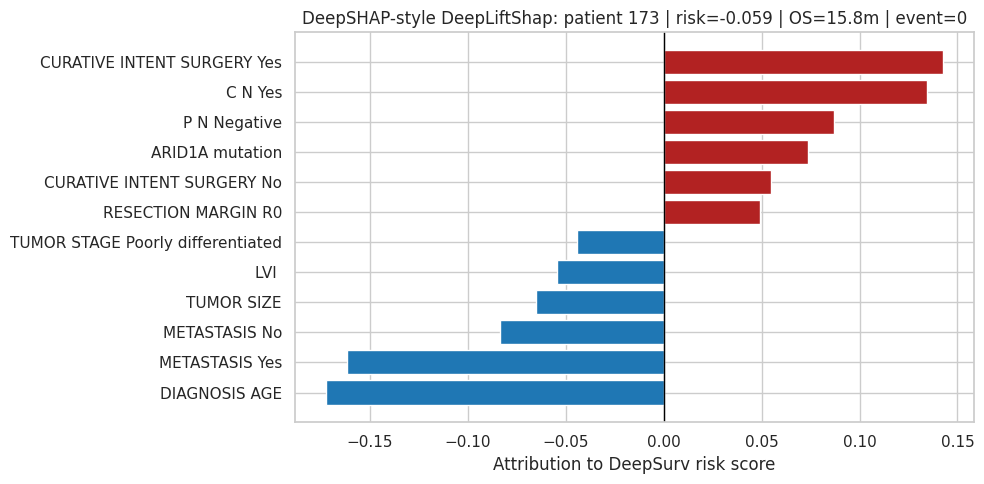

High-risk observed death


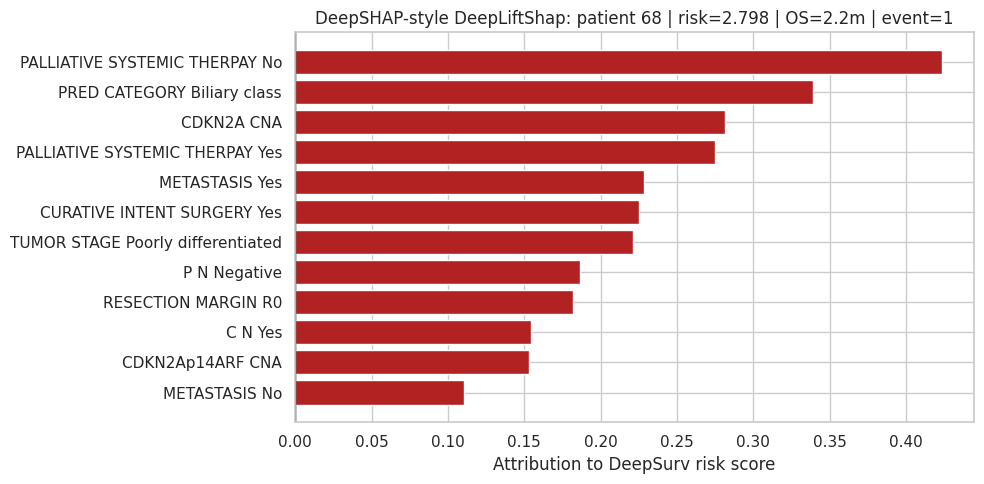

In [22]:
for _, patient in representative_patients.iterrows():
    print(patient["patient_type"])
    plot_waterfall_for_patient(
        deepshap_attr_df,
        int(patient["test_index"]),
        "DeepSHAP-style DeepLiftShap",
        top_n=TOP_N_WATERFALL
    )

Integrated Gradients attribution

In [23]:
set_seed(RANDOM_STATE)

integrated_gradients = IntegratedGradients(xai_model)
ig_baselines = median_baseline.repeat(X_test_tensor.shape[0], 1)

ig_attr = integrated_gradients.attribute(
    X_test_tensor,
    baselines=ig_baselines,
    n_steps=50
).detach().cpu().numpy()

ig_importance, ig_attr_df = build_importance_table(
    ig_attr,
    "Integrated Gradients"
)

ig_gene_top = display_top_tables(
    ig_importance,
    "Integrated Gradients"
)

Top 20 full features by Integrated Gradients


,feature,mean_abs_attribution,mean_signed_attribution,positive_attribution_fraction,method,readable_label,feature_group,gene_symbol,is_gene_feature,direction,rank
0,METASTASIS_Yes,0.127486,0.127486,0.319853,Integrated Gradients,METASTASIS Yes,Clinical / pathology,NaN,False,Risk-increasing,1
1,CURATIVE_INTENT_SURGERY_Yes,0.125726,-0.125726,0.000000,Integrated Gradients,CURATIVE INTENT SURGERY Yes,Treatment / surgery,NaN,False,Protective,2
2,PALLIATIVE_SYSTEMIC_THERPAY_No,0.089377,-0.020770,0.080882,Integrated Gradients,PALLIATIVE SYSTEMIC THERPAY No,Other,NaN,False,Protective,3
3,TUMOR_SIZE,0.087935,0.015369,0.327206,Integrated Gradients,TUMOR SIZE,Clinical / pathology,NaN,False,Risk-increasing,4
4,PALLIATIVE_SYSTEMIC_THERPAY_Yes,0.079440,-0.031384,0.080882,Integrated Gradients,PALLIATIVE SYSTEMIC THERPAY Yes,Other,NaN,False,Protective,5
5,P_N_Negative,0.074636,-0.074636,0.000000,Integrated Gradients,P N Negative,Clinical / pathology,NaN,False,Protective,6
6,METASTASIS_No,0.066663,0.066663,0.330882,Integrated Gradients,METASTASIS No,Clinical / pathology,NaN,False,Risk-increasing,7
7,DIAGNOSIS_AGE,0.064070,0.000071,0.514706,Integrated Gradients,DIAGNOSIS AGE,Demographic,NaN,False,Risk-increasing,8
8,RESECTION_MARGIN_R0,0.061188,-0.061188,0.000000,Integrated Gradients,RESECTION MARGIN R0,Treatment / surgery,NaN,False,Protective,9
9,P_N_,0.057699,-0.015884,0.367647,Integrated Gradients,P N,Clinical / pathology,NaN,False,Protective,10


Top 30 gene-derived features by Integrated Gradients


,feature,mean_abs_attribution,mean_signed_attribution,positive_attribution_fraction,method,readable_label,feature_group,gene_symbol,is_gene_feature,direction,rank
14,CNA_CDKN2A,0.037324,0.037090,0.106618,Integrated Gradients,CDKN2A CNA,Copy number alteration,CDKN2A,True,Risk-increasing,15
17,MUT_KRAS,0.027003,0.027003,0.128676,Integrated Gradients,KRAS mutation,Mutation,KRAS,True,Risk-increasing,18
19,CNA_CDKN2Ap14ARF,0.025442,0.025302,0.102941,Integrated Gradients,CDKN2Ap14ARF CNA,Copy number alteration,CDKN2Ap14ARF,True,Risk-increasing,20
27,CNA_TP53,0.016285,0.016285,0.007353,Integrated Gradients,TP53 CNA,Copy number alteration,TP53,True,Risk-increasing,28
30,MUT_ARID1A,0.014033,0.012278,0.128676,Integrated Gradients,ARID1A mutation,Mutation,ARID1A,True,Risk-increasing,31
32,CNA_CDKN2B,0.012649,0.011494,0.088235,Integrated Gradients,CDKN2B CNA,Copy number alteration,CDKN2B,True,Risk-increasing,33
33,CNA_AXL,0.011903,-0.011903,0.000000,Integrated Gradients,AXL CNA,Copy number alteration,AXL,True,Protective,34
39,MUT_CD276,0.006300,0.006300,0.003676,Integrated Gradients,CD276 mutation,Mutation,CD276,True,Risk-increasing,40
41,CNA_CDKN2Ap16INK4A,0.006085,-0.000773,0.029412,Integrated Gradients,CDKN2Ap16INK4A CNA,Copy number alteration,CDKN2Ap16INK4A,True,Protective,42
42,MUT_SHQ1,0.003136,0.003136,0.003676,Integrated Gradients,SHQ1 mutation,Mutation,SHQ1,True,Risk-increasing,43


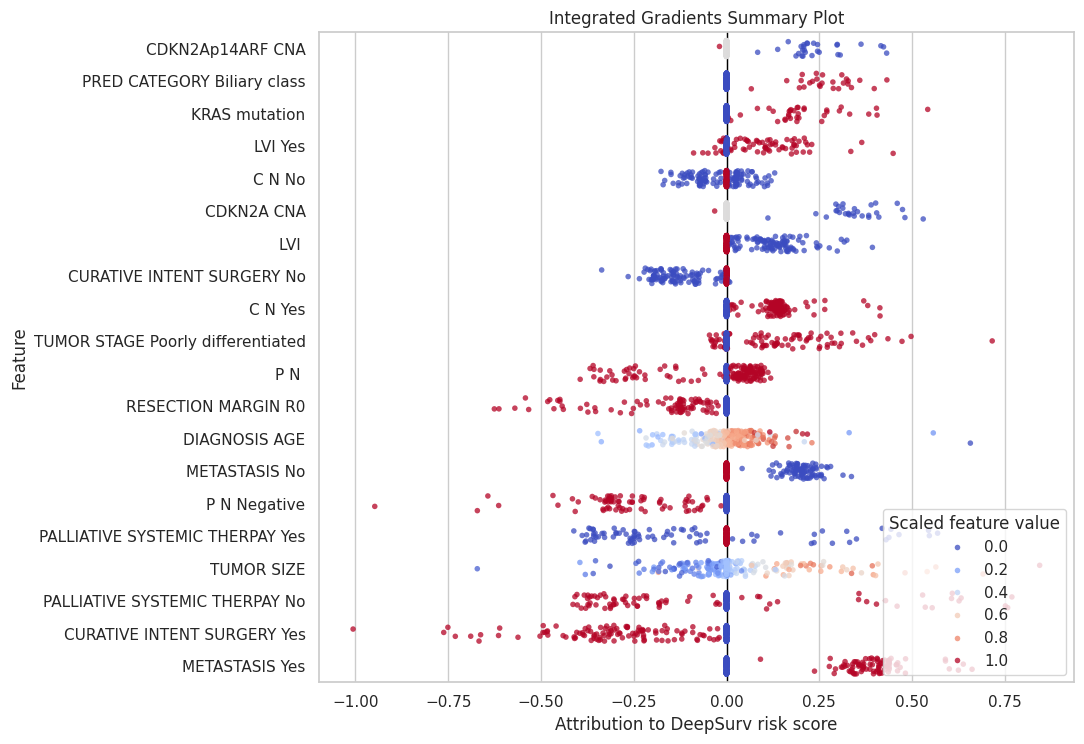

In [24]:
plot_summary_beeswarm(
    ig_attr_df,
    X_test,
    ig_importance,
    "Integrated Gradients Summary Plot",
    top_n=TOP_N_FEATURES
)

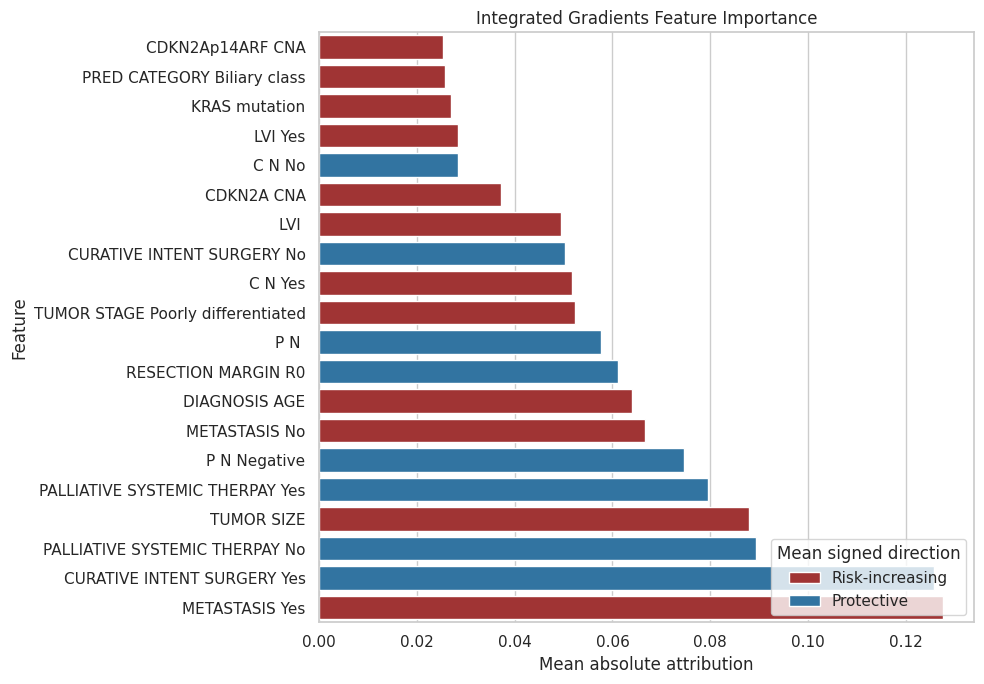

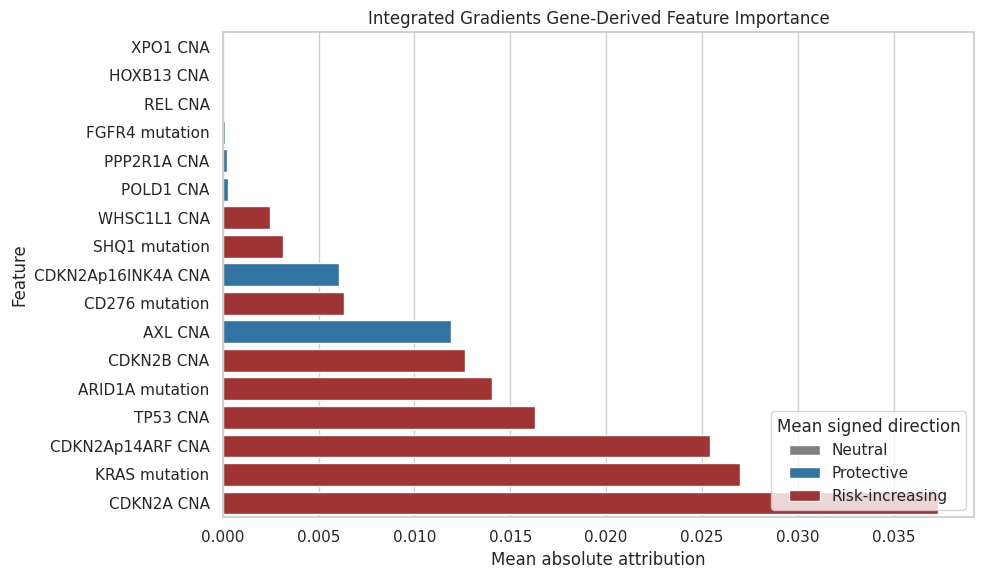

In [25]:
plot_importance_bar(
    ig_importance,
    "Integrated Gradients Feature Importance",
    top_n=TOP_N_FEATURES,
    gene_only=False
)

plot_importance_bar(
    ig_importance,
    "Integrated Gradients Gene-Derived Feature Importance",
    top_n=min(TOP_N_GENES, int(feature_metadata["is_gene_feature"].sum())),
    gene_only=True
)

Integrated Gradients waterfall plots for representative patients

Highest predicted risk


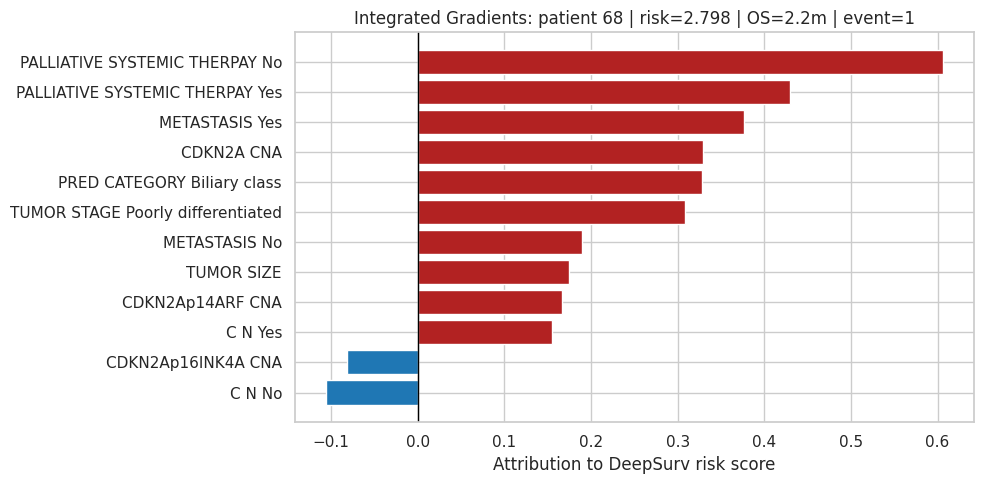

Lowest predicted risk


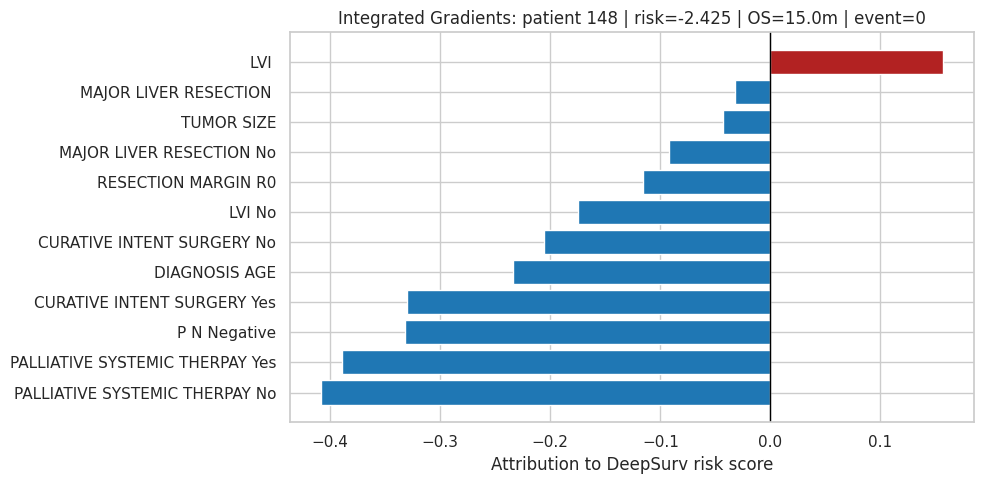

Median predicted risk


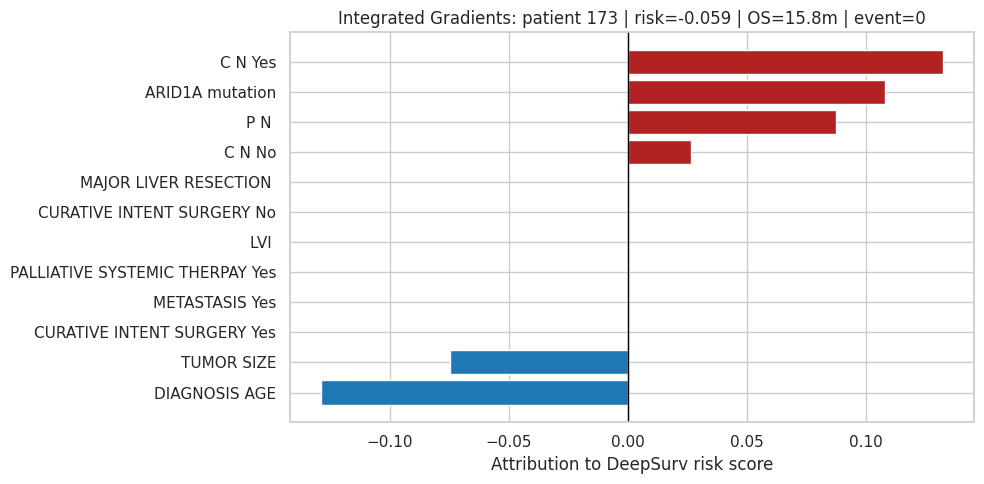

High-risk observed death


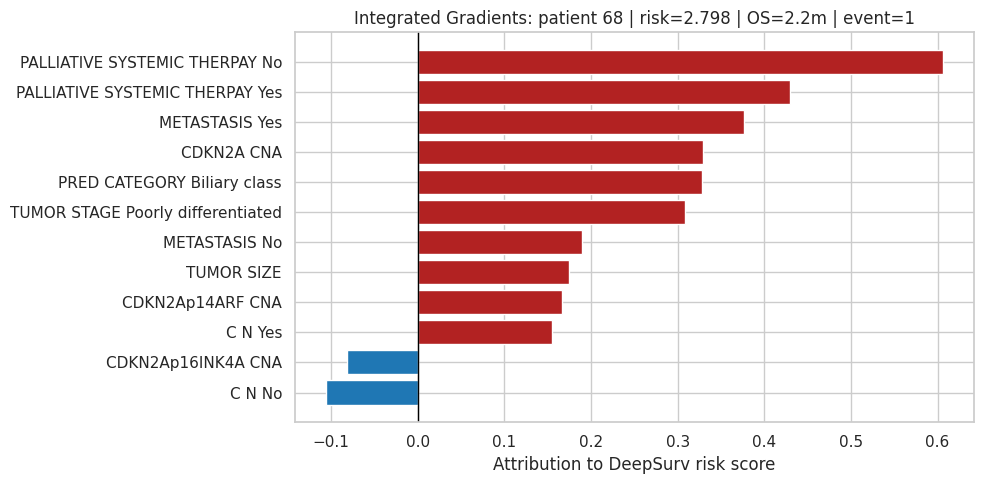

In [26]:
for _, patient in representative_patients.iterrows():
    print(patient["patient_type"])
    plot_waterfall_for_patient(
        ig_attr_df,
        int(patient["test_index"]),
        "Integrated Gradients",
        top_n=TOP_N_WATERFALL
    )

In [27]:
set_seed(RANDOM_STATE)

gradient_shap = GradientShap(xai_model)

gradientshap_attr = gradient_shap.attribute(
    X_test_tensor,
    baselines=background_tensor,
    n_samples=25,
    stdevs=0.01
).detach().cpu().numpy()

gradientshap_importance, gradientshap_attr_df = build_importance_table(
    gradientshap_attr,
    "GradientSHAP"
)

gradientshap_gene_top = display_top_tables(
    gradientshap_importance,
    "GradientSHAP"
)

Top 20 full features by GradientSHAP


,feature,mean_abs_attribution,mean_signed_attribution,positive_attribution_fraction,method,readable_label,feature_group,gene_symbol,is_gene_feature,direction,rank
0,CURATIVE_INTENT_SURGERY_Yes,0.213116,0.007414,0.591912,GradientSHAP,CURATIVE INTENT SURGERY Yes,Treatment / surgery,NaN,False,Risk-increasing,1
1,METASTASIS_Yes,0.188401,-0.052990,0.319853,GradientSHAP,METASTASIS Yes,Clinical / pathology,NaN,False,Protective,2
2,RESECTION_MARGIN_R0,0.170058,-0.041682,0.683824,GradientSHAP,RESECTION MARGIN R0,Treatment / surgery,NaN,False,Protective,3
3,P_N_Negative,0.164759,0.021585,0.724265,GradientSHAP,P N Negative,Clinical / pathology,NaN,False,Risk-increasing,4
4,C_N_Yes,0.103623,-0.001716,0.363971,GradientSHAP,C N Yes,Clinical / pathology,NaN,False,Protective,5
5,TUMOR_STAGE_Poorly differentiated,0.100842,-0.012185,0.323529,GradientSHAP,TUMOR STAGE Poorly differentiated,Clinical / pathology,NaN,False,Protective,6
6,DIAGNOSIS_AGE,0.093827,-0.022485,0.444853,GradientSHAP,DIAGNOSIS AGE,Demographic,NaN,False,Protective,7
7,PALLIATIVE_SYSTEMIC_THERPAY_No,0.092127,-0.016575,0.430147,GradientSHAP,PALLIATIVE SYSTEMIC THERPAY No,Other,NaN,False,Protective,8
8,METASTASIS_No,0.090106,-0.025548,0.330882,GradientSHAP,METASTASIS No,Clinical / pathology,NaN,False,Protective,9
9,LVI_,0.082365,-0.006030,0.386029,GradientSHAP,LVI,Clinical / pathology,NaN,False,Protective,10


Top 30 gene-derived features by GradientSHAP


,feature,mean_abs_attribution,mean_signed_attribution,positive_attribution_fraction,method,readable_label,feature_group,gene_symbol,is_gene_feature,direction,rank
15,MUT_KRAS,0.053427,0.009429,0.172794,GradientSHAP,KRAS mutation,Mutation,KRAS,True,Risk-increasing,16
17,CNA_CDKN2A,0.049399,0.015241,0.209559,GradientSHAP,CDKN2A CNA,Copy number alteration,CDKN2A,True,Risk-increasing,18
21,CNA_AXL,0.035687,-0.034618,0.411765,GradientSHAP,AXL CNA,Copy number alteration,AXL,True,Protective,22
23,CNA_CDKN2Ap14ARF,0.034318,0.010134,0.220588,GradientSHAP,CDKN2Ap14ARF CNA,Copy number alteration,CDKN2Ap14ARF,True,Risk-increasing,24
32,MUT_CD276,0.020050,-0.006919,0.419118,GradientSHAP,CD276 mutation,Mutation,CD276,True,Protective,33
33,MUT_ARID1A,0.017793,0.004794,0.408088,GradientSHAP,ARID1A mutation,Mutation,ARID1A,True,Risk-increasing,34
35,CNA_PPP2R1A,0.017295,-0.016835,0.422794,GradientSHAP,PPP2R1A CNA,Copy number alteration,PPP2R1A,True,Protective,36
36,CNA_TP53,0.017266,0.016064,0.547794,GradientSHAP,TP53 CNA,Copy number alteration,TP53,True,Risk-increasing,37
38,CNA_POLD1,0.017174,-0.016763,0.330882,GradientSHAP,POLD1 CNA,Copy number alteration,POLD1,True,Protective,39
41,CNA_CDKN2B,0.010275,0.000873,0.397059,GradientSHAP,CDKN2B CNA,Copy number alteration,CDKN2B,True,Risk-increasing,42


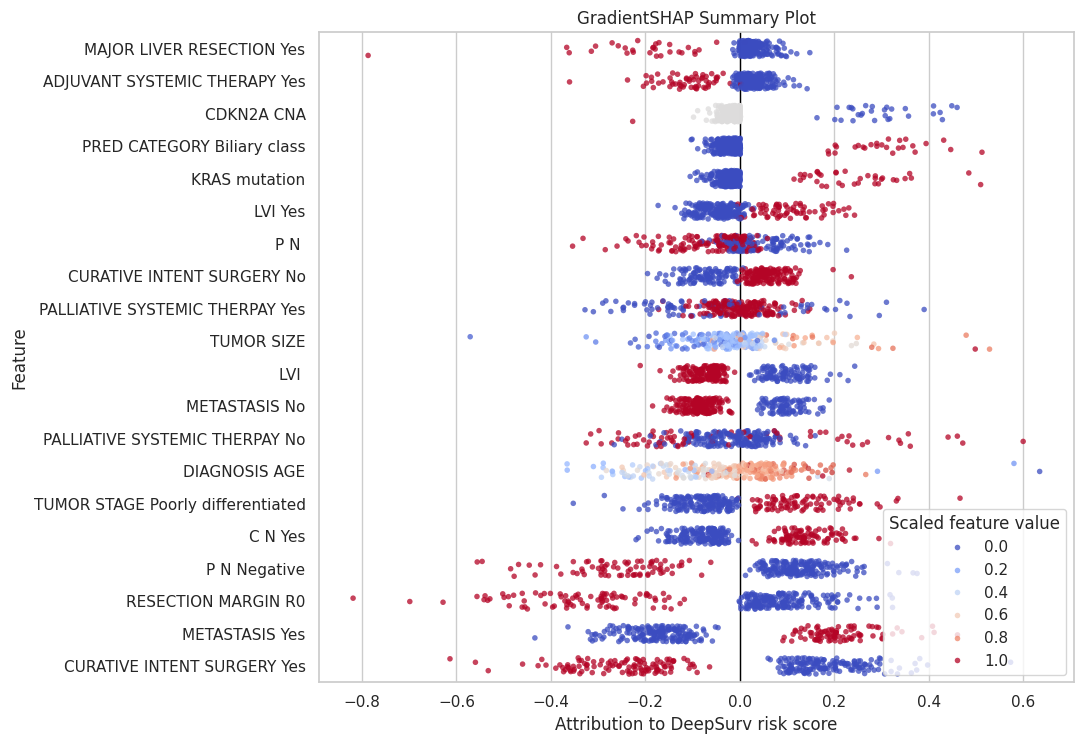

In [28]:
plot_summary_beeswarm(
    gradientshap_attr_df,
    X_test,
    gradientshap_importance,
    "GradientSHAP Summary Plot",
    top_n=TOP_N_FEATURES
)

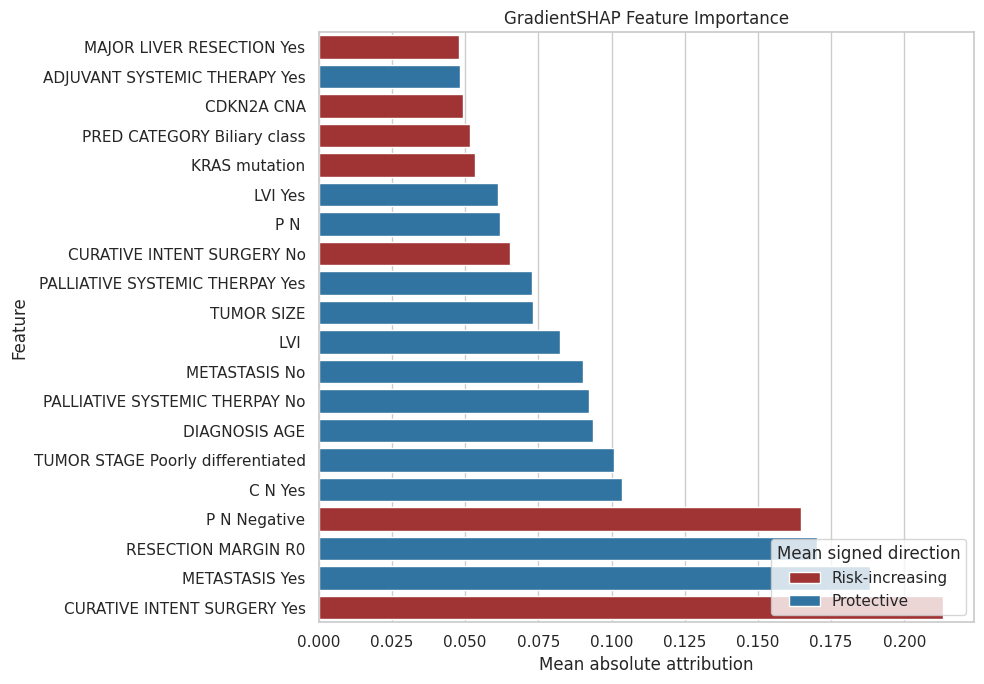

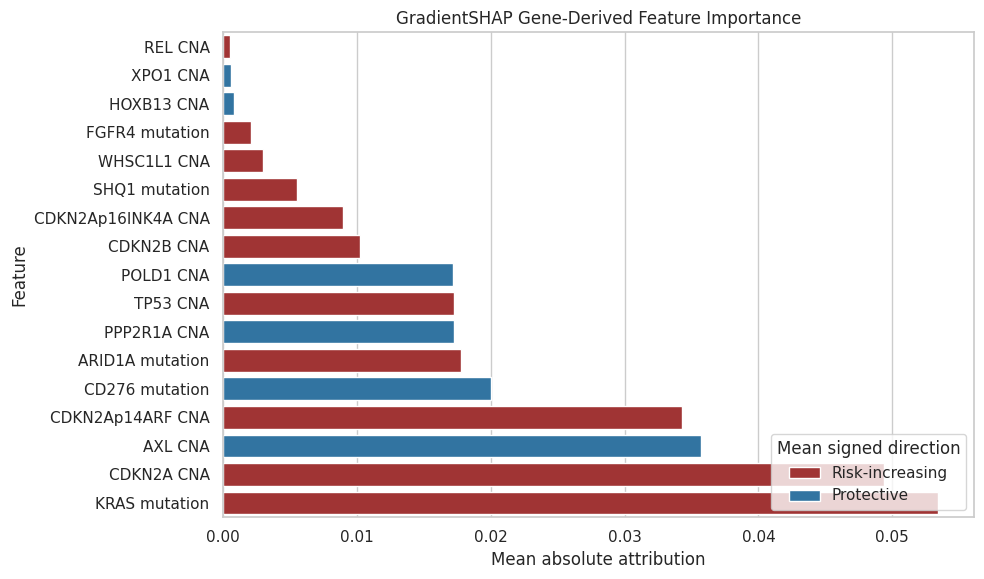

In [29]:
plot_importance_bar(
    gradientshap_importance,
    "GradientSHAP Feature Importance",
    top_n=TOP_N_FEATURES,
    gene_only=False
)

plot_importance_bar(
    gradientshap_importance,
    "GradientSHAP Gene-Derived Feature Importance",
    top_n=min(TOP_N_GENES, int(feature_metadata["is_gene_feature"].sum())),
    gene_only=True
)

GradientSHAP waterfall plots for representative patients

Highest predicted risk


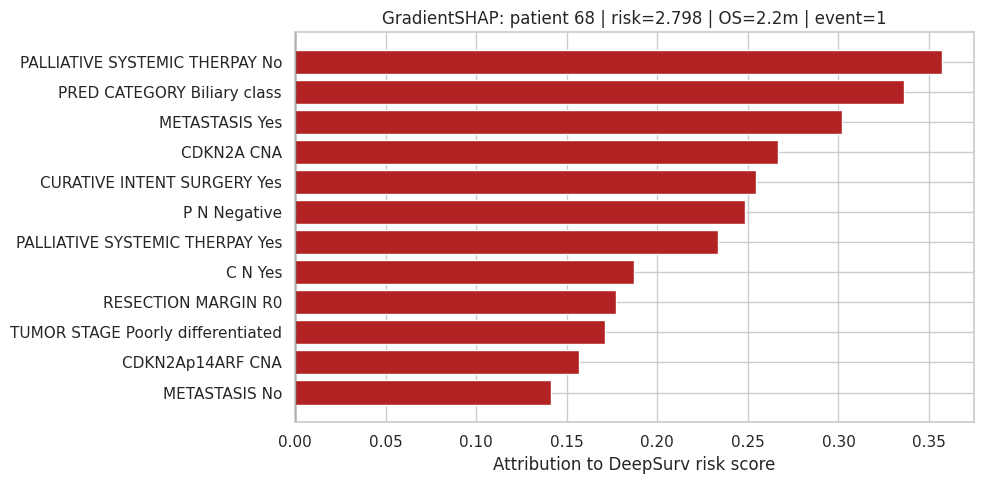

Lowest predicted risk


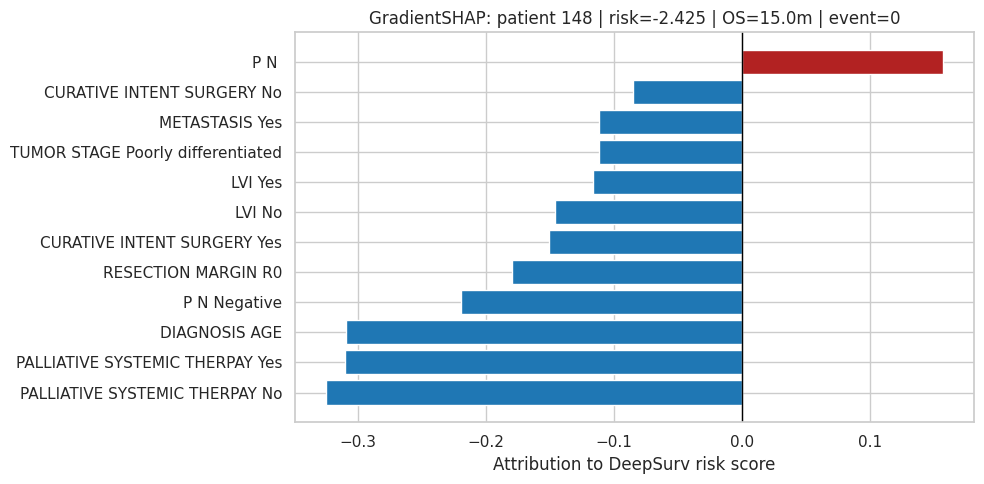

Median predicted risk


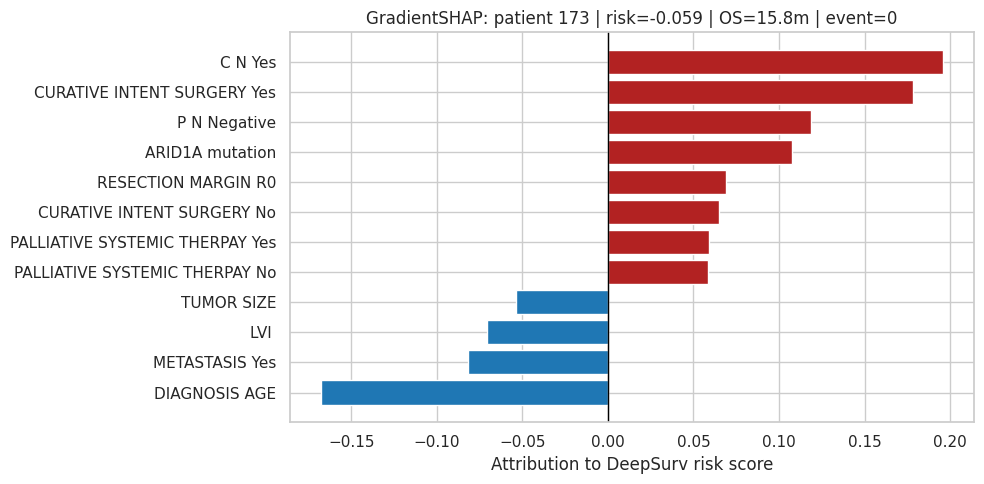

High-risk observed death


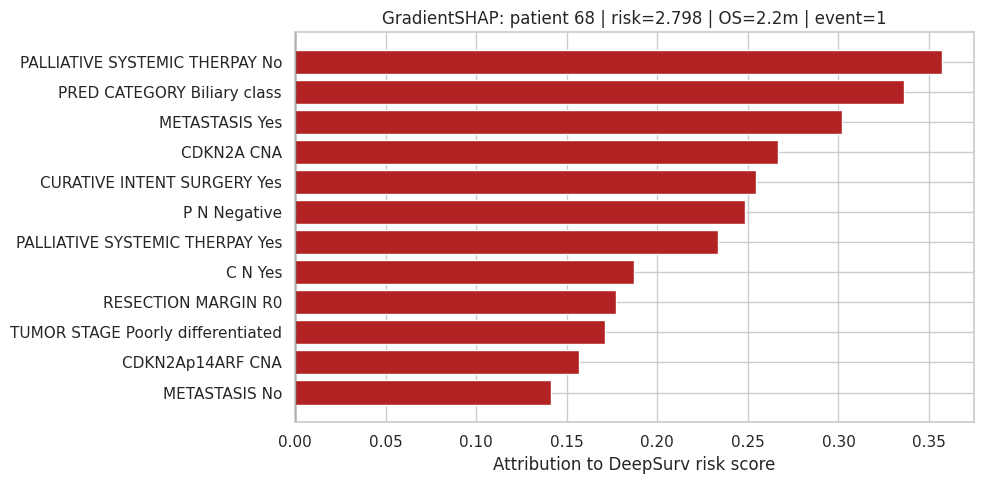

In [30]:
for _, patient in representative_patients.iterrows():
    print(patient["patient_type"])
    plot_waterfall_for_patient(
        gradientshap_attr_df,
        int(patient["test_index"]),
        "GradientSHAP",
        top_n=TOP_N_WATERFALL
    )

Lightweight background sensitivity check
This checks whether DeepSHAP-style top feature rankings are stable when using a second random background sample. This is a diagnostic, not the final consensus analysis.

In [31]:
set_seed(RANDOM_STATE + 1)

background_indices_2 = (
    X_train
    .sample(n=background_size, random_state=RANDOM_STATE + 1)
    .index
)
background_tensor_2 = torch.tensor(
    X_train.loc[background_indices_2].values,
    dtype=torch.float32
).to(DEVICE)

deepshap_attr_2 = deeplift_shap.attribute(
    X_test_tensor,
    baselines=background_tensor_2
).detach().cpu().numpy()

deepshap_importance_2, _ = build_importance_table(
    deepshap_attr_2,
    "DeepSHAP-style DeepLiftShap background 2"
)

rank_compare = deepshap_importance[["feature", "rank"]].merge(
    deepshap_importance_2[["feature", "rank"]],
    on="feature",
    suffixes=("_background_1", "_background_2")
)

spearman_rank_correlation = spearmanr(
    rank_compare["rank_background_1"],
    rank_compare["rank_background_2"]
).correlation

top20_background_1 = set(deepshap_importance.head(20)["feature"])
top20_background_2 = set(deepshap_importance_2.head(20)["feature"])
top20_overlap = len(top20_background_1.intersection(top20_background_2))

print("Spearman rank correlation:", round(float(spearman_rank_correlation), 4))
print("Top 20 feature overlap:", top20_overlap, "of 20")

rank_compare.sort_values("rank_background_1").head(20)

Spearman rank correlation: 0.9507
Top 20 feature overlap: 19 of 20


,feature,rank_background_1,rank_background_2
0,CURATIVE_INTENT_SURGERY_Yes,1,1
1,METASTASIS_Yes,2,2
2,P_N_Negative,3,3
3,RESECTION_MARGIN_R0,4,4
4,TUMOR_STAGE_Poorly differentiated,5,6
5,C_N_Yes,6,5
6,METASTASIS_No,7,10
7,PALLIATIVE_SYSTEMIC_THERPAY_No,8,7
8,LVI_,9,9
9,DIAGNOSIS_AGE,10,8


In [32]:
deepshap_top_genes = set(deepshap_gene_top.head(20)["gene_symbol"].dropna())
ig_top_genes = set(ig_gene_top.head(20)["gene_symbol"].dropna())
gradientshap_top_genes = set(gradientshap_gene_top.head(20)["gene_symbol"].dropna())

all_top_genes = sorted(deepshap_top_genes | ig_top_genes | gradientshap_top_genes)

preview_rows = []
for gene in all_top_genes:
    preview_rows.append({
        "gene": gene,
        "in_deepshap_top20": gene in deepshap_top_genes,
        "in_integrated_gradients_top20": gene in ig_top_genes,
        "in_gradientshap_top20": gene in gradientshap_top_genes,
        "method_count": sum([
            gene in deepshap_top_genes,
            gene in ig_top_genes,
            gene in gradientshap_top_genes
        ])
    })

method_overlap_preview = (
    pd.DataFrame(preview_rows)
    .sort_values(["method_count", "gene"], ascending=[False, True])
    .reset_index(drop=True)
)

method_overlap_preview

,gene,in_deepshap_top20,in_integrated_gradients_top20,in_gradientshap_top20,method_count
0,ARID1A,True,True,True,3
1,AXL,True,True,True,3
2,CD276,True,True,True,3
3,CDKN2A,True,True,True,3
4,CDKN2Ap14ARF,True,True,True,3
5,CDKN2Ap16INK4A,True,True,True,3
6,CDKN2B,True,True,True,3
7,FGFR4,True,True,True,3
8,HOXB13,True,True,True,3
9,KRAS,True,True,True,3


In [33]:
deepshap_importance.to_csv(XAI_RESULTS_DIR + "unicox_deepsurv_deepshap_full_feature_importance.csv", index=False)
ig_importance.to_csv(XAI_RESULTS_DIR + "unicox_deepsurv_integrated_gradients_full_feature_importance.csv", index=False)
gradientshap_importance.to_csv(XAI_RESULTS_DIR + "unicox_deepsurv_gradientshap_full_feature_importance.csv", index=False)

deepshap_gene_top.to_csv(XAI_RESULTS_DIR + "unicox_deepsurv_deepshap_top_gene_features.csv", index=False)
ig_gene_top.to_csv(XAI_RESULTS_DIR + "unicox_deepsurv_integrated_gradients_top_gene_features.csv", index=False)
gradientshap_gene_top.to_csv(XAI_RESULTS_DIR + "unicox_deepsurv_gradientshap_top_gene_features.csv", index=False)

method_overlap_preview.to_csv(XAI_RESULTS_DIR + "unicox_deepsurv_xai_top20_gene_overlap_preview.csv", index=False)

print("Saved XAI ranking outputs to:", XAI_RESULTS_DIR)

Saved XAI ranking outputs to: /content/drive/MyDrive/IEEE Project/Hepatocellular Carcinoma/Results/XAI/
